# Volatility Dynamics 09 — compound-Poisson jumps

**VD 019.** Module 08 found that volatility-standardized jumps ($|\tilde r|>4$ local $\sigma$) arrive like a homogeneous Poisson process per asset, with ~20% of jump bars shared by several assets. Module 09 describes them as a compound-Poisson process: catalogue, sizes, market-wide vs idiosyncratic arrivals, tick check, and $P(\ge1\text{ jump in }\tau)=1-e^{-\lambda\tau}$.

Detection is Module 08's, unchanged ($c=4$).

**Pre-registered (VD 019 §3):**
- **P1** — a common-jump component exists iff bars with ≥ 2 assets jumping exceed the independence expectation with one-sided Poisson $p<0.01$.
- **P2** — an asset is a tick-discreteness artifact iff its median jump is ≤ 3 index ticks; it is then excluded from Module 10.
- **P3** — GPD vs exponential tail on $z-c$ (reported).
- **P4** — first- vs second-half rate stability (reported, Holm).

Inputs: `state_time`, `underlying`, `return_5m`, `futures_index_price`. Outputs: `09/`.

In [1]:
from pathlib import Path
import json, os, sys, time, warnings
import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
from dotenv import load_dotenv

warnings.filterwarnings('ignore', category=RuntimeWarning)
warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', 200)
pd.set_option('display.width', 300)
pd.set_option('display.max_rows', 300)

load_dotenv()
DATA_ROOT = Path(os.environ['DERIBIT_DATA_ROOT']).expanduser().resolve()
DB_PATH = DATA_ROOT / 'database' / 'research.duckdb'
PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent and not (PROJECT_ROOT / 'src' / 'data_engineering').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / 'src' / 'data_engineering').exists():
    raise RuntimeError('Repository root not found.')
SRC = PROJECT_ROOT / 'src'
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

from data_engineering.modeling import volatility_vd_b_core as vb
from data_engineering.modeling import volatility_jump_compound as jc
START = os.getenv('VD9_START', '').strip() or None
END = os.getenv('VD9_END', '').strip() or None
ASSETS = [x.strip().upper() for x in os.getenv('VD9_ASSETS', '').split(',') if x.strip()]

OUT = PROJECT_ROOT / 'notebooks' / 'Volatility_Dynamics' / '09'
OUT.mkdir(parents=True, exist_ok=True)
print('Module 09', jc.VERSION, jc.selftest())


Module 09 0.1.0 {'garwood': True, 'poisson_sf': True, 'tail_fit': True, 'no_false_common_component': True, 'common_component_detected': True, 'tick_artifact_detected': True}


In [2]:
def qident(name):
    return '"' + str(name).replace('"', '""') + '"'

def load_frame(columns, start=None, end=None, assets=None):
    cols = list(dict.fromkeys(['state_time', 'underlying', 'return_5m'] + list(columns)))
    where = []
    if start:
        ts = pd.Timestamp(start)
        ts = ts.tz_localize('UTC') if ts.tzinfo is None else ts.tz_convert('UTC')
        where.append(f"state_time >= TIMESTAMPTZ '{ts.isoformat()}'")
    if end:
        ts = pd.Timestamp(end)
        ts = ts.tz_localize('UTC') if ts.tzinfo is None else ts.tz_convert('UTC')
        where.append(f"state_time < TIMESTAMPTZ '{(ts + pd.Timedelta(days=1)).isoformat()}'")
    if assets:
        where.append('underlying IN (' + ','.join(repr(x) for x in assets) + ')')
    sql = ('SELECT ' + ', '.join(qident(c) for c in cols) + ' FROM time_series_feature_state'
           + ('' if not where else ' WHERE ' + ' AND '.join(where)) + ' ORDER BY underlying, state_time')
    con = duckdb.connect(str(DB_PATH), read_only=True)
    try:
        df = con.execute(sql).df()
    finally:
        con.close()
    if df.empty:
        raise RuntimeError('No rows found.')
    df['state_time'] = pd.to_datetime(df['state_time'], utc=True)
    if df.duplicated(['underlying', 'state_time']).any():
        raise RuntimeError('Duplicate asset/timestamp rows.')
    print(f'rows {len(df):,} | assets {sorted(df.underlying.unique())} | {df.state_time.min()} -> {df.state_time.max()}')
    return df.reset_index(drop=True)

def schema_columns():
    con = duckdb.connect(str(DB_PATH), read_only=True)
    try:
        return con.execute('DESCRIBE time_series_feature_state').df()
    finally:
        con.close()

df = load_frame(['futures_index_price'], START, END, ASSETS)
grid = vb.build_grid(df)
res = jc.run(grid)
cat = res['catalog']
print('jumps:', len(cat))
display(res['rates'].round(3))
print(json.dumps(res['cojump'], indent=2, default=float))


rows 42,336 | assets ['AVAX', 'BTC', 'ETH', 'HYPE', 'SOL', 'TRX', 'XRP'] | 2026-09-19 08:00:00+00:00 -> 2026-10-10 07:55:00+00:00
jumps: 245


,underlying,valid_days,n_jumps,rate_per_day,rate_ci_low,rate_ci_high,n_common,n_idiosyncratic,common_share
0,AVAX,17.885,29,1.621,1.086,2.329,15,14,0.517
1,BTC,17.885,38,2.125,1.504,2.916,21,17,0.553
2,ETH,17.885,33,1.845,1.270,2.591,24,9,0.727
3,HYPE,17.885,15,0.839,0.469,1.383,3,12,0.200
4,SOL,17.885,27,1.510,0.995,2.196,20,7,0.741
5,TRX,17.878,75,4.195,3.300,5.258,5,70,0.067
6,XRP,17.885,28,1.566,1.040,2.263,21,7,0.750


{
  "observed_bars_ge2": 34,
  "expected_bars_ge2_independent": 4.684990120506073,
  "ratio": 7.257219145710241,
  "poisson_p_one_sided": 1.1102230246251565e-16,
  "common_component": true
}


,underlying,n_jumps,share_up,bps_q25,bps_median,bps_q75,bps_q95,bps_max,z_median,z_q90,z_max,mean_excess_z,gpd_xi,gpd_vs_exp_lr_p
0,AVAX,29,0.414,84.619,131.434,161.866,223.893,230.293,4.773,6.375,7.428,1.027,-0.21,0.438
1,BTC,38,0.579,19.296,33.764,46.265,79.019,112.049,4.745,5.660,7.070,0.876,-0.28,0.108
2,ETH,33,0.485,29.180,45.210,77.727,109.992,166.519,4.673,8.030,8.999,1.335,0.21,0.448
3,HYPE,15,0.600,53.036,65.503,95.842,142.003,148.433,4.393,5.622,6.029,0.679,-0.28,0.440
4,SOL,27,0.556,42.889,59.583,84.984,148.066,213.748,4.742,7.147,13.377,1.339,0.35,0.077
5,TRX,75,0.373,11.565,15.924,19.792,31.208,54.502,4.997,7.446,13.393,1.541,0.08,0.483
6,XRP,28,0.393,46.810,73.765,124.009,149.244,188.785,4.704,6.701,7.564,1.056,-0.11,0.651
7,ALL,245,0.461,18.363,40.704,78.495,154.251,230.293,4.769,6.821,13.393,1.219,0.11,0.062


,underlying,index_tick,median_price,tick_bps,n_jumps,median_jump_ticks,share_jumps_le3_ticks,tick_artifact
0,AVAX,0.0010,10.9550,0.9128,29,135.0000,0.0,False
1,BTC,18.2500,84318.9900,2.1644,38,15.6033,0.0,False
2,ETH,0.0100,2688.5500,0.0372,33,1153.0000,0.0,False
3,HYPE,0.0010,90.4120,0.1106,15,607.0000,0.0,False
4,SOL,0.0002,118.8567,0.0168,27,3459.5000,0.0,False
5,TRX,0.0000,0.3358,0.0298,75,532.0000,0.0,False
6,XRP,0.0000,1.5003,0.1333,28,552.5000,0.0,False


,underlying,jumps_first_half,jumps_second_half,rate_ratio_second_over_first,binomial_p,holm_p
0,AVAX,18,11,0.6592,0.3532,1.0
1,BTC,18,20,1.1985,0.6281,1.0
2,ETH,16,17,1.1461,0.7301,1.0
3,HYPE,10,5,0.5393,0.3070,1.0
4,SOL,15,12,0.8630,0.8478,1.0
5,TRX,36,39,1.1677,0.5638,1.0
6,XRP,13,15,1.2446,0.5768,1.0


,underlying,tau_hours,p_at_least_one_jump,p_ci_low,p_ci_high
1,AVAX,4,0.2368,0.1656,0.3217
2,AVAX,8,0.4175,0.3037,0.5399
3,AVAX,16,0.6607,0.5152,0.7883
6,BTC,4,0.2982,0.2217,0.3849
7,BTC,8,0.5075,0.3942,0.6217
8,BTC,16,0.7574,0.6330,0.8569
11,ETH,4,0.2647,0.1908,0.3507
12,ETH,8,0.4594,0.3452,0.5784
13,ETH,16,0.7077,0.5712,0.8223
16,HYPE,4,0.1304,0.0753,0.2059


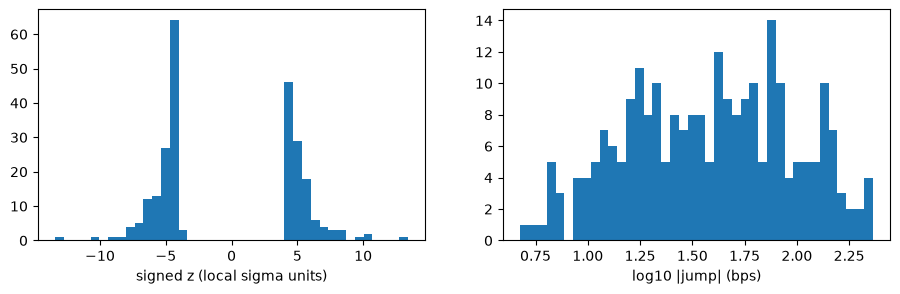

In [3]:
display(res['sizes'].round(3))
display(res['ticks'].round(4))
display(res['stability'].round(4))
display(res['probabilities'][res['probabilities'].tau_hours.isin([4, 8, 16])].round(4))
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
axes[0].hist(cat['signed_z'], bins=40); axes[0].set_xlabel('signed z (local sigma units)')
axes[1].hist(np.log10(cat['abs_return_bps']), bins=40); axes[1].set_xlabel('log10 |jump| (bps)')
plt.show()


In [4]:
cat.to_csv(OUT / '09_jump_catalog.csv', index=False)
res['sizes'].to_csv(OUT / '09_jump_sizes.csv', index=False)
res['rates'].to_csv(OUT / '09_arrival_rates.csv', index=False)
res['probabilities'].to_csv(OUT / '09_jump_probability_to_tau.csv', index=False)
res['ticks'].to_csv(OUT / '09_tick_check.csv', index=False)
res['stability'].to_csv(OUT / '09_rate_stability.csv', index=False)
decision = {
    'P1_common_component': res['cojump'],
    'P2_tick_artifact_assets': res['ticks'].loc[res['ticks'].tick_artifact, 'underlying'].tolist(),
    'P3_tail_all': res['sizes'][res['sizes'].underlying == 'ALL'].iloc[0][['gpd_xi', 'gpd_vs_exp_lr_p']].to_dict(),
    'P4_unstable_assets_holm05': res['stability'].loc[res['stability'].holm_p < 0.05, 'underlying'].tolist(),
}
(OUT / '09_decision.json').write_text(json.dumps(decision, indent=2, default=float))
meta = {'version': jc.VERSION, 'module': '09_compound_poisson_jumps', 'c': jc.C,
        'first_time': str(df.state_time.min()), 'last_time': str(df.state_time.max()), 'n_rows': int(len(df)),
        'n_jumps': int(len(cat))}
(OUT / '09_run_metadata.json').write_text(json.dumps(meta, indent=2))
print(json.dumps(decision, indent=2, default=float))


{
  "P1_common_component": {
    "observed_bars_ge2": 34,
    "expected_bars_ge2_independent": 4.684990120506073,
    "ratio": 7.257219145710241,
    "poisson_p_one_sided": 1.1102230246251565e-16,
    "common_component": true
  },
  "P2_tick_artifact_assets": [],
  "P3_tail_all": {
    "gpd_xi": 0.11000000000000004,
    "gpd_vs_exp_lr_p": 0.06193457668820235
  },
  "P4_unstable_assets_holm05": []
}
